# Histogram Algorithm

List tài liệu tham khảo:

Opencv Document - Histogram 

Slide


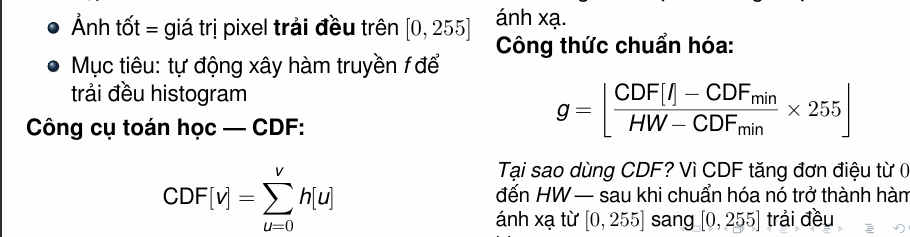

In [12]:
import cv2
import numpy as np

Original Image

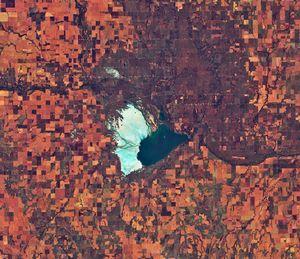

In [35]:
img2 = cv2.imread("H:\\HK1_2026-2027\\ComputerVision\\Code\\anhTest.jpg")
img2


array([[[127, 115, 173],
        [ 52,  39,  95],
        [ 43,  31,  81],
        ...,
        [ 95,  93, 145],
        [ 67,  59, 129],
        [ 73,  63, 140]],

       [[123, 111, 171],
        [ 56,  42, 100],
        [ 47,  31,  84],
        ...,
        [ 86,  85, 141],
        [ 81,  75, 146],
        [ 91,  82, 162]],

       [[111, 100, 163],
        [ 61,  46, 107],
        [ 51,  35,  89],
        ...,
        [ 97,  96, 162],
        [103, 101, 177],
        [109, 106, 186]],

       ...,

       [[115, 143, 227],
        [106, 131, 211],
        [ 90, 108, 179],
        ...,
        [ 90, 117, 198],
        [ 81, 107, 197],
        [ 80, 106, 200]],

       [[ 98, 133, 219],
        [103, 133, 214],
        [105, 127, 199],
        ...,
        [ 80, 101, 182],
        [ 74,  94, 182],
        [ 73,  94, 186]],

       [[116, 150, 234],
        [112, 142, 221],
        [109, 128, 201],
        ...,
        [ 73,  95, 173],
        [ 68,  88, 175],
        [ 71,  90, 181]]

In [28]:
img = cv2.imread("H:\\HK1_2026-2027\\ComputerVision\\Code\\anhTest.jpg", cv2.IMREAD_GRAYSCALE)
img


array([[134,  57,  47, ..., 109,  81,  87],
       [130,  61,  49, ..., 102,  97, 107],
       [120,  66,  53, ..., 116, 124, 130],
       ...,
       [165, 152, 127, ..., 138, 131, 131],
       [155, 154, 146, ..., 123, 118, 119],
       [171, 162, 148, ..., 116, 112, 115]], shape=(259, 300), dtype=uint8)

In [29]:
img.shape #High = 100, Weight = 100, RGB

(259, 300)

In [30]:
# Option 1 to calculate Hist
hist = cv2.calcHist([img], [0], None, [256], [0, 256])
# Hist is a 256x1 array, each value corresponds to number of pixels in
# that image with its corresponding pixel value

In [31]:
# Option 2 is using numpy
HIST, bins = np.histogram(img.ravel(), 256, [0, 256])

## Plot it

### Method 1

In [32]:
from matplotlib import pyplot as plt

C:\Users\Wuan\AppData\Local\Temp\ipykernel_27096\2918830310.py:1: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  plt.hist(img.ravel(), 256, [0, 256])


(array([0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 2.000e+00,
        3.000e+00, 1.000e+00, 1.000e+00, 7.000e+00, 4.000e+00, 4.000e+00,
        1.100e+01, 1.000e+01, 1.200e+01, 1.600e+01, 1.500e+01, 3.200e+01,
        3.100e+01, 3.700e+01, 3.000e+01, 4.700e+01, 7.500e+01, 7.300e+01,
        9.800e+01, 9.900e+01, 1.160e+02, 1.110e+02, 1.450e+02, 1.470e+02,
        1.890e+02, 2.110e+02, 2.620e+02, 2.710e+02, 3.200e+02, 3.600e+02,
        3.920e+02, 3.610e+02, 3.850e+02, 4.260e+02, 4.410e+02, 4.400e+02,
        4.830e+02, 5.430e+02, 5.840e+02, 6.860e+02, 6.840e+02, 6.820e+02,
        7.690e+02, 8.010e+02, 9.400e+02, 9.480e+02, 9.870e+02, 1.046e+03,
        1.068e+03, 1.149e+03, 1.134e+03, 1.214e+03, 1.211e+03, 1.277e+03,
        1.271e+03, 1.248e+03, 1.271e+03, 1.208e+03, 1.176e+03, 1.131e+03,
        1.139e+03, 1.127e+03, 1.054e+0

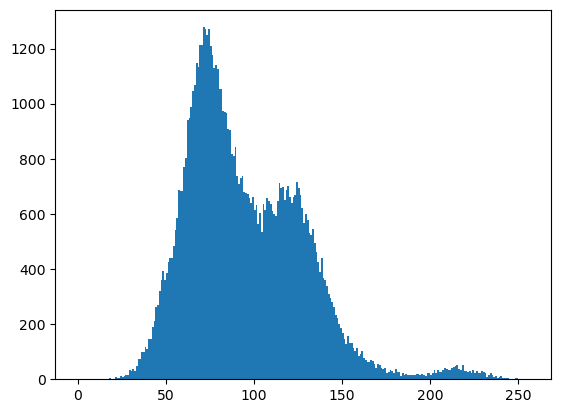

In [34]:
plt.hist(img.ravel(), 256, [0, 256])

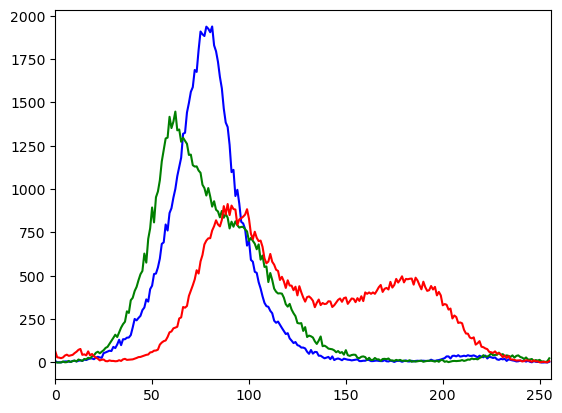

In [41]:
color = ('b', 'g', 'r')
for i, col in enumerate(color):
    histr = cv2.calcHist([img2], [i], None, [256], [0, 256])
    plt.plot(histr, color = col)
    plt.xlim([0, 256])
plt.show()

### Method 2: Opencv

(0.0, 256.0)

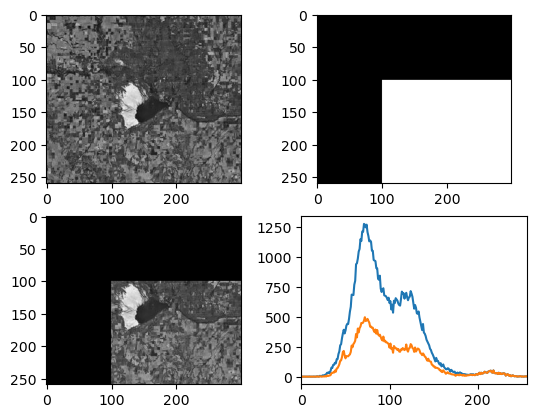

In [43]:
# Đoạn code mẫu sau là copy full, chỉ có thay đổi cv -> cv2
mask = np.zeros(img.shape[:2], np.uint8)
mask[100:300, 100:400] = 255
masked_img = cv2.bitwise_and(img,img,mask = mask)

## Calculate histogram with mask and without mask
## Check third argument for mask
hist_full = cv2.calcHist([img],[0],None,[256],[0,256])
hist_mask = cv2.calcHist([img],[0],mask,[256],[0,256])

plt.subplot(221), plt.imshow(img, 'gray')
plt.subplot(222), plt.imshow(mask,'gray')
plt.subplot(223), plt.imshow(masked_img, 'gray')
plt.subplot(224), plt.plot(hist_full), plt.plot(hist_mask)
plt.xlim([0,256])